### Assignment-6

In [13]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score,confusion_matrix,f1_score,recall_score,precision_score,r2_score,mean_absolute_error,mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

In [2]:
df = pd.read_csv("Downloads/archive/uber.csv")
df.info()
df.isnull().sum()

df.dropna(inplace=True)

df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [3]:
# remove unnecessary column
df.drop(["Unnamed: 0","key"],axis=1,inplace=True)

# remove invalid data
df = df[df["fare_amount"]>0]

df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


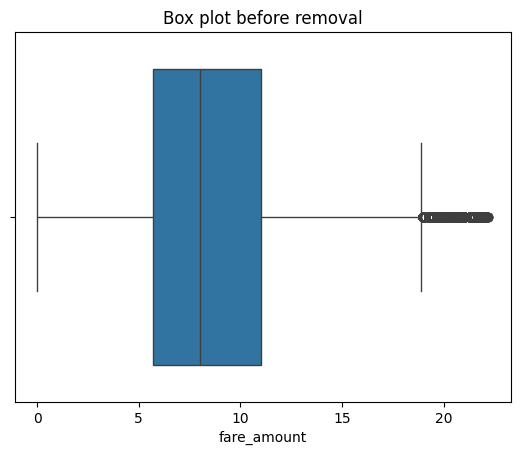

Lower: 0
Upper: 18.95


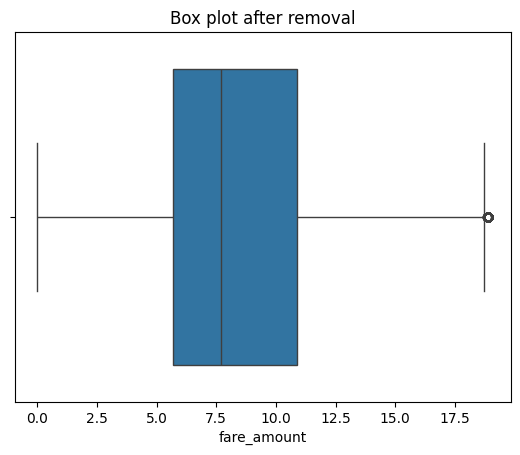

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df["fare_amount"])
plt.title("Box plot before removal")
plt.show()

q1 = df["fare_amount"].quantile(0.25)
q3 = df["fare_amount"].quantile(0.75)

IQR = q3 - q1
lower = max(0,q1 - 1.5*IQR)
upper = q3 + 1.5*IQR
print("Lower:",lower)
print("Upper:",upper)
df= df[(df["fare_amount"]>=lower) & (df["fare_amount"]<=upper)]

sns.boxplot(x=df["fare_amount"])
plt.title("Box plot after removal")
plt.show()

Text(0.5, 1.0, 'Correlation between numeric columns')

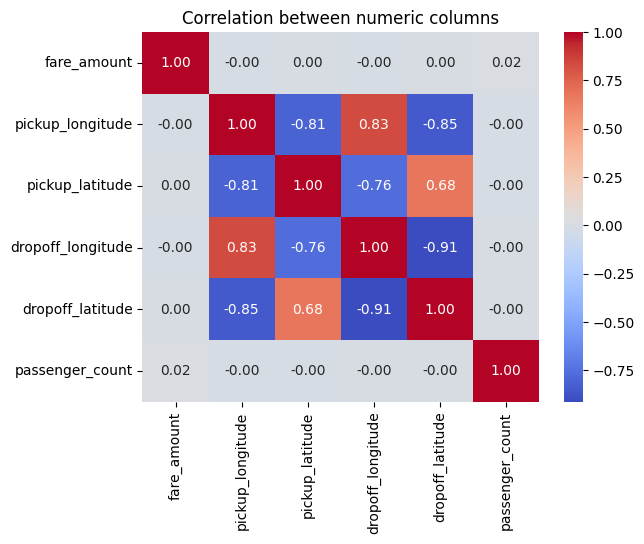

In [8]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr,annot=True,fmt=".2f",cmap="coolwarm")
plt.title("Correlation between numeric columns")

In [16]:
from sklearn.model_selection import train_test_split

x = df[["pickup_longitude","pickup_latitude","dropoff_longitude","dropoff_latitude","passenger_count"]]
y = df["fare_amount"]

X_train,X_test,Y_train,Y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
)

lr = LinearRegression()
lr.fit(X_train,Y_train)
y_pred_lr = lr.predict(X_test)

# rfc = RandomForestRegressor(n_estimators=100,random_state = 42,n_jobs=-1)
rfc = RandomForestRegressor()
rfc.fit(X_train,Y_train)
y_pred_rfc = rfc.predict(X_test)


print("Model Metrics\n")
print("LinearRegression Model:\n")
print("R2 score",r2_score(Y_test,y_pred_lr))
print("RMSE",np.sqrt(mean_squared_error(Y_test,y_pred_lr)))
print("MSE",mean_squared_error(Y_test,y_pred_lr))
print("MAE",mean_absolute_error(Y_test,y_pred_lr))

print("\nRandom Forest Model:")
print("R2 score",r2_score(Y_test,y_pred_rfc))
print("RMSE",np.sqrt(mean_squared_error(Y_test,y_pred_rfc)))
print("MSE",mean_squared_error(Y_test,y_pred_rfc))
print("MAE",mean_absolute_error(Y_test,y_pred_rfc))

Model Metrics

LinearRegression Model:

R2 score 0.0002545189001043058
RMSE 3.658809627384908
MSE 13.386887889444488
MAE 2.9628889528773996

Random Forest Model:
R2 score 0.6866442274490048
RMSE 2.0483960894461135
MSE 4.19592653925813
MAE 1.4645765394482344
